# Primer zadatka klasterizacije teksta

U fajlu “E-Commerce_Reviews_for_class.csv” su dati podaci sa komentarima kupaca jedne
online prodavnice o kupljenoj odeći. Fajl sadrži više kolona (varijabli) od kojih su za ovaj
zadatak relevantne samo kolone `Title` i `Review Text`.

Koristeći podatke iz navedenog fajla, potrebno je uraditi sledeće:


* Kreirati novu kolonu **`review_content`** koja objedinjuje sadržaj kolona Title i Review Text
(kroz obično nadovezivanje stringova).


* Transformisati sadržaj kolone review_content u vektorsku (tj. numeričku) reprezentaciju
primenom pristupa zasnovanom na vektorima dokumenata (document vectors), i
konkretno vektorskim reprezentacijama koje generiše “all-MiniLM-L12-v2” Sentence
Transformers model (model je lokalno dostupan).


* Izvršiti klasterizaciju (transformisanih) novinskih tekstova primenom aglomerativnog
hijerarhijskog klasterovanja. Odrediti optimalni broj klastera na osnovu dendrograma i
siluet skora (silhouette score). Obrazložiti izbor optimalnog broja klastera.


* Za svaki od klastera odrediti top 10 reči / izraza na osnovu TF-IDF metrike.


* Odrediti veličinu svakog od klastera i opisati svaki klaster na osnovu identifikovanih top
10 reči / izraza, i eventualnog uvida u naslove / sadržaj komentara u okviru klastera.

In [1]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path
from IPython.display import display

from sentence_transformers import SentenceTransformer

import spacy

# SPACY_MODEL = 'en_core_web_sm' # or 'en_core_web_md'

In [2]:
RAND_STATE = 1
LM_MODEL = 'all-MiniLM-L12-v2'

Ucitavanje i priprema podataka

In [3]:
data = pd.read_csv(Path.cwd() / 'data'/ 'E-Commerce_Reviews_for_class.csv')
data.head()

,Clothing ID,Age,Title,Review Text,Rating
0,833,50,More beautiful in person,I bought this in the store and love it. seeing...,4
1,1046,66,Wonderful,This wide leg pant gives the perception of a s...,5
2,945,23,Not for me,I ordered this with another sweater to compare...,4
3,1094,45,"For curvy or tall, not for the waist challenged","The fabric, so diaphanous! so flowy! the patte...",3
4,840,57,Comfortable,A nice rayon peasant shirt - like the sleeve l...,5


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Clothing ID  3000 non-null   int64
 1   Age          3000 non-null   int64
 2   Title        3000 non-null   str  
 3   Review Text  3000 non-null   str  
 4   Rating       3000 non-null   int64
dtypes: int64(3), str(2)
memory usage: 117.3 KB


In [5]:
data.duplicated().sum()

np.int64(0)

In [6]:
data['review_content'] = data.apply(lambda row: f"{row['Title']}. {row['Review Text']}", axis=1)
data.head()

,Clothing ID,Age,Title,Review Text,Rating,review_content
0,833,50,More beautiful in person,I bought this in the store and love it. seeing...,4,More beautiful in person. I bought this in the...
1,1046,66,Wonderful,This wide leg pant gives the perception of a s...,5,Wonderful. This wide leg pant gives the percep...
2,945,23,Not for me,I ordered this with another sweater to compare...,4,Not for me. I ordered this with another sweate...
3,1094,45,"For curvy or tall, not for the waist challenged","The fabric, so diaphanous! so flowy! the patte...",3,"For curvy or tall, not for the waist challenge..."
4,840,57,Comfortable,A nice rayon peasant shirt - like the sleeve l...,5,Comfortable. A nice rayon peasant shirt - like...


Proveravamo broj reci u svakom tekstu kako bismo utvrdili da li tekstovi prekoracuju ogranicenje modela od 256 tokena. Ako je potrebno, tekstove skracujemo na oko 200 reci.

In [7]:
data['review_len'] = data.review_content.apply(lambda txt: len(txt.split()))

data.review_len.describe()

count    3000.000000
mean       64.664333
std        28.621275
min         6.000000
25%        41.000000
50%        63.000000
75%        93.000000
max       118.000000
Name: review_len, dtype: float64

Nema potrebe za skracivanjem jer je max duzina teksta u ovom setu podataka 118 reci.

### Transformacija komentara u numericke vektore

In [8]:
transformer = SentenceTransformer(LM_MODEL, local_files_only=True)
embeddings = transformer.encode(data.review_content.to_numpy())
embeddings.shape

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

(3000, 384)

### Racunanje slicnosti i klasterizacija

In [9]:
cos_dist = 1 - cosine_similarity(embeddings, embeddings)
cos_dist.shape

(3000, 3000)

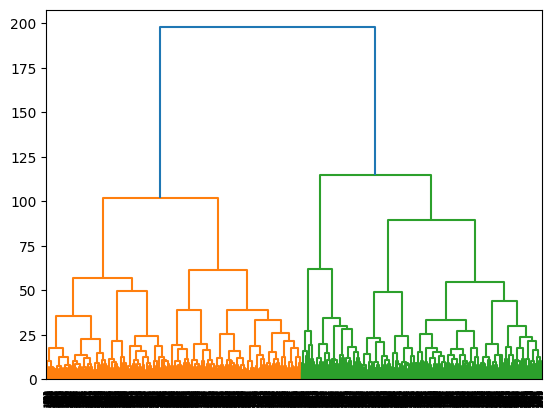

In [10]:
ward_linkage = sch.linkage(cos_dist, method='ward')

plt.figure()
sch.dendrogram(ward_linkage)
plt.show()

Na osnovu dendograma, mozemo da zakljucimo da bi optimalan broj klastera mogao da bude izmedju 2 i 5.

In [11]:
k_range = range(2,6)
s_scores = []

cos_dist_clipped = np.clip(cos_dist, a_min=0.0, a_max=None)
for k in k_range:
    k_clusters = sch.fcluster(ward_linkage,
                              t=k,
                              criterion='maxclust')
    score = silhouette_score(cos_dist_clipped,
                             k_clusters,
                             metric='precomputed')
    s_scores.append(score)

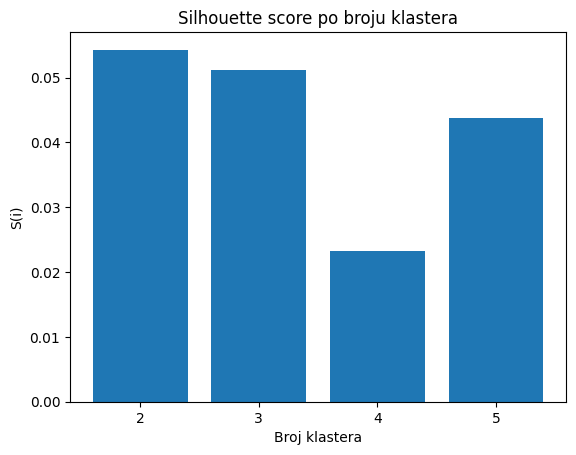

In [12]:
plt.bar(k_range, s_scores)
plt.title('Silhouette score po broju klastera')
plt.xlabel('Broj klastera')
plt.ylabel('S(i)')
plt.xticks(k_range)
plt.show()

Iako je za dva klastera silhouette score najveci, posto je malo veci od skora za tri, prvo cemo probati da uradimo klasterizaciju za tri klastera jer je generalno bolja praksa.

In [13]:
cluster_opt = sch.fcluster(ward_linkage,
                           t=3,
                           criterion='maxclust')
data['cluster'] = cluster_opt
data.cluster.value_counts()

cluster
1    1545
3    1094
2     361
Name: count, dtype: int64

Raspodela clanaka po klasterima nije idealno uravnotezena, jer klasteri nemaju priblizno isti broj elemenata.
To nam sugerise da ipak izaberemo 2 klastera.

In [14]:
cluster_opt = sch.fcluster(ward_linkage,
                           t=2,
                           criterion='maxclust')
data['cluster'] = cluster_opt
data.cluster.value_counts()

cluster
1    1545
2    1455
Name: count, dtype: int64

### Odredjivanje kljucnih reci

In [15]:
def get_top_ngrams(cluster_id, words_to_remove=None):
    vectorizer = TfidfVectorizer(
        stop_words='english',
        ngram_range=(1,2),
        min_df=0.01,
        max_df=0.95
    )
    cluster_reviews = data.loc[data.cluster==cluster_id,'review_content']
    cluster_tfidf = vectorizer.fit_transform(cluster_reviews)
    candidate_keywords = vectorizer.get_feature_names_out()

    mean_tfidf = np.asarray(cluster_tfidf.mean(axis=1)).flatten()

    sorted_candidates = sorted([(kw,tfidf) for kw,tfidf in zip(candidate_keywords, mean_tfidf)],
                               key=lambda x:x[1],
                               reverse=True)

    if words_to_remove:
        sorted_candidates = [(kw,sc) for kw,sc in sorted_candidates if
                             kw not in words_to_remove]
    return sorted_candidates[:10]

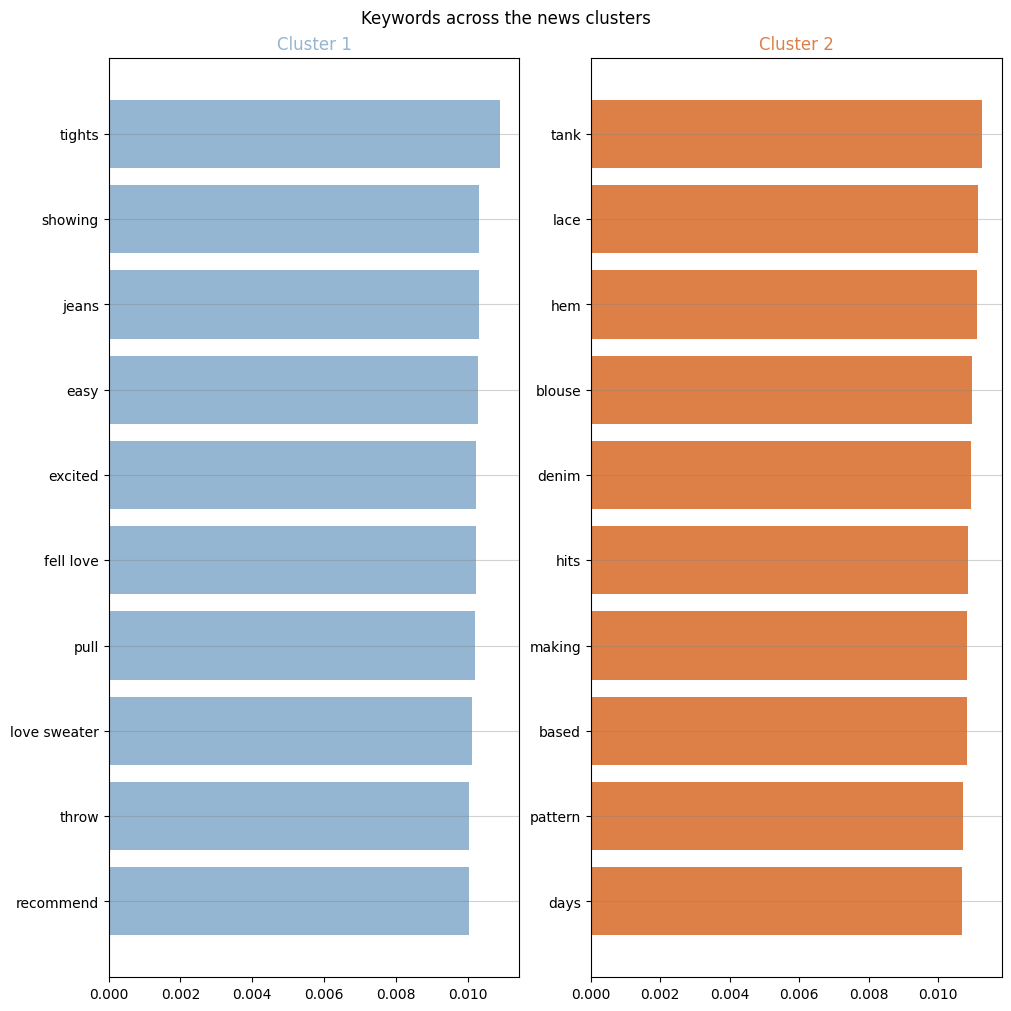

In [16]:
from pypalettes import load_cmap

fig, ax_grid = plt.subplots(nrows=1, ncols=2, figsize=(10, 10), constrained_layout=True)
axes = ax_grid.flatten()

cmap = load_cmap("excel_Median")

n_clust = data['cluster'].nunique()
for i in range(n_clust):

    scored_kwds = get_top_ngrams(i+1)
    scored_kwds = sorted(scored_kwds, key=lambda item: item[1])
    scores = [s for kw, s in scored_kwds]
    keywords = [kw for kw, s in scored_kwds]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Cluster {i+1}", color=cmap(i))
    axes[i].grid(visible=True, axis='y', color='gray', alpha=0.35)

# za slucaj da je kreirano vise plotova nego sto je potrebno za prikaz (npr. grid 2x2, za prikaz 3 klastera)
# axes[n_clust].remove()

fig.suptitle("Keywords across the news clusters")

plt.show()

In [17]:
data.loc[data.cluster==1,'Title'].sample(n=10, random_state=RAND_STATE)

2567                   Versatile comfortable dress
958     Gingham garden dress renamed and new color
1249                                     Weird fit
2430                                      Love it!
2483                                  So adorable!
913                               Very cute, short
2386                                 Easy to wear!
2628                      Feels like comfy pajamas
532                    Great quality - runs narrow
526                       Great little denim dress
Name: Title, dtype: str

In [18]:
data.loc[data.cluster==2,'Title'].sample(n=10, random_state=RAND_STATE)

2798       Beautiful...runs very small
2751                      Sweater time
2221                Every woman's cami
1888                 Way too scratchy!
92                          Love these
2490                          Gorgeous
2597                 Rip favorite pair
224     This might be my new favorite!
2594                    Perfect pair!!
2301             Love this sweater....
Name: Title, dtype: str

Na osnovu uzoraka naslova za oba klastera, mozemo da damo grubu procenu o kontekstu:
* klaster 1: haljine i uglavnom pozitivni komentari
* klaster 2: farmerke, pantalone i dzemperi